<a href="https://colab.research.google.com/github/26005165/data-science-toolkit/blob/main/Tutorial3-example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Loading a dataset into google colab (2ways)
# Way 1
# Drag and drop dataset into google colab, but everytime close and open again the google colab, then need to drag and drop again
# Way 2 (more preferrable)
# Upload to google drive and then code it to link and take dataset from GD


In [13]:
# Question 1
# 1. Find some real dataset. Load it on Colab, Kaggle etc. Try to visualize some of it

import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/titanic/train.csv')
display(df.head())



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [12]:
# Question 2
# 2. Evaluate if the data is good or not. Does it have enough samples?

print("Rows and columns: ", df.shape)
print("Repeated PassengerId values: ", df["PassengerId"].duplicated().sum())
print("Survived values (0 = No, 1 = Yes):")
print(df["Survived"].value_counts())


Rows and columns:  (891, 12)
Repeated PassengerId values:  0
Survived values(0 = No, 1 = Yes):
Survived
0    549
1    342
Name: count, dtype: int64


In [14]:
# Question 3
# 3. How many features does it have? Is it enough?

print("All columns: ")
print(df.columns.tolist())
print("Number of columns: ", len(df.columns))
print("Possible input columns (excluding Survived): ", len(df.columns)-1)

# There are 13 columns: one outcome (Survived) and 11 other columns
# Survived is the target, while other 11 columns is the features
# Normally, in every dataset, there is a target column.


All columns: 
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Number of columns:  12
Possible input columns (excluding Survived):  11


In [15]:
# Question 4
# 4. How many samples/observation does it have? Is it enough?

print("Number of passengers: ", len(df))

# Answer: 891 observations in the standard Kaggle train.csv.
# That is enough to calculate summaries and create beginner charts, but whether it is sufficient for a reliable prediction model depends.


Number of passengers:  891


In [17]:
# Question 5
# 5. What are the datatypes does the dataset consist of?

print(df.dtypes)

# int64 means whole numbers (e.g., number of family members);
# float64 means decimal numbers (e.g., age or fare);
# object usually means text (e.g., passenger name or sex)

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [18]:
# 6. How many columns have null values? If yes, which column, which rows
# 8. Does it have missing values? If yes, which column, which row.

missing = df.isnull().sum()
print("Missing values in each column: ")
print(missing)
print("\nColumns with any missing values: ")
print(missing[missing>0])
print("\nNumber of columns with missing values: ", (missing > 0).sum())

Missing values in each column: 
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Columns with any missing values: 
Age         177
Cabin       687
Embarked      2
dtype: int64

Number of columns with missing values:  3


In [20]:
# Question 7
# 7. Which column is the feature, which is the target output?

target = "Survived"
features = df.drop(columns=["Survived", "PassengerId"])

print("Target: ",target)
print("Example feature columns: ", features.columns.tolist())
print("Target values: ", df[target].unique())

# Answer: Target is Survived (0=did not survive; 1=survived).
# The features are passenger details used to investigate survival.
# PassengerId is excluded from our example features because it identifies a passenger rather than describing their circumstances.
# No prediction model is trained in this exercise.

Target:  Survived
Example feature columns:  ['Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Target values:  [0 1]


Percentage who survived in each class: 
Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64


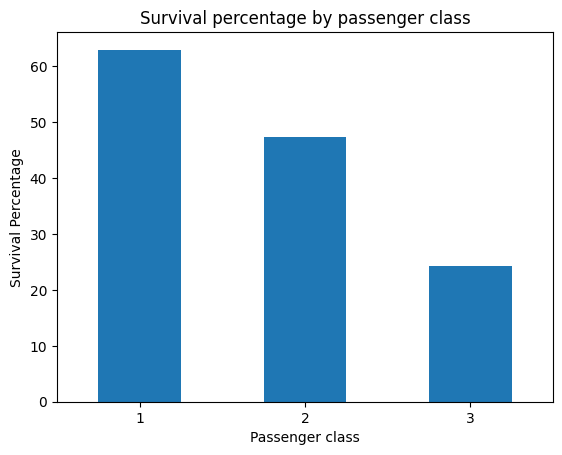

In [22]:
# Question 9
# 9. What kind of question can be asked, should we ask. Does the dataset suits the question we are asking?

# Suggested question: How did survival rates differ by passenger class?
# This is suitable becasue Pclass (1st, 2nd, 3rd class) and Survived are both present.
# The following table shows proportions rather than only passenger counts.
import matplotlib.pyplot as plt

survival_rate = df.groupby("Pclass")["Survived"].mean()*100
print("Percentage who survived in each class: ")
print(survival_rate.round(1))

survival_rate.plot(kind="bar")
plt.title("Survival percentage by passenger class")
plt.xlabel("Passenger class")
plt.ylabel("Survival Percentage")
plt.xticks(rotation=0)
plt.show()



In [21]:
#axis=1 means you are checking the rows horizontally one by one.
#axis=0 means ging down the columns
rows_missing = df[df.isnull().any(axis=1)]
print("Number of rows with at least one missing values: ", len(rows_missing))
print("First 10 rows containing missing values: ")
display(rows_missing.head(10))

# To find EXACT positions for one particular column:
column_to_check = "Age"
print("Passenger IDs with missing", column_to_check, ":")
print(df.loc[df[column_to_check].isnull(), "PassengerId"].tolist())

Number of rows with at least one missing values:  708
First 10 rows containing missing values: 


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C
12,13,0,3,"Saundercock, Mr. William Henry",male,20.0,0,0,A/5. 2151,8.0500,NaN,S
13,14,0,3,"Andersson, Mr. Anders Johan",male,39.0,1,5,347082,31.2750,NaN,S
14,15,0,3,"Vestrom, Miss. Hulda Amanda Adolfina",female,14.0,0,0,350406,7.8542,NaN,S


Passenger IDs with missing Age :
[6, 18, 20, 27, 29, 30, 32, 33, 37, 43, 46, 47, 48, 49, 56, 65, 66, 77, 78, 83, 88, 96, 102, 108, 110, 122, 127, 129, 141, 155, 159, 160, 167, 169, 177, 181, 182, 186, 187, 197, 199, 202, 215, 224, 230, 236, 241, 242, 251, 257, 261, 265, 271, 275, 278, 285, 296, 299, 301, 302, 304, 305, 307, 325, 331, 335, 336, 348, 352, 355, 359, 360, 365, 368, 369, 376, 385, 389, 410, 411, 412, 414, 416, 421, 426, 429, 432, 445, 452, 455, 458, 460, 465, 467, 469, 471, 476, 482, 486, 491, 496, 498, 503, 508, 512, 518, 523, 525, 528, 532, 534, 539, 548, 553, 558, 561, 564, 565, 569, 574, 579, 585, 590, 594, 597, 599, 602, 603, 612, 613, 614, 630, 634, 640, 644, 649, 651, 654, 657, 668, 670, 675, 681, 693, 698, 710, 712, 719, 728, 733, 739, 740, 741, 761, 767, 769, 774, 777, 779, 784, 791, 793, 794, 816, 826, 827, 829, 833, 838, 840, 847, 850, 860, 864, 869, 879, 889]
